Angelyn Nathasya Br Marpaung 

Time series forecasting menggunakan data transaksi saham FB dan IBM.

## Libraries

In [40]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print(f"Libraries imported successfully!")

Libraries imported successfully!


## Load data

In [41]:
df1= pd.read_csv("Dataset D/FB.csv")

print(f"Training data shape: {df1.shape}")
df1.head()

Training data shape: (1980, 7)


,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-05-18,42.049999,45.000000,38.000000,38.230000,38.230000,573576400
1,2012-05-21,36.529999,36.660000,33.000000,34.029999,34.029999,168192700
2,2012-05-22,32.610001,33.590000,30.940001,31.000000,31.000000,101786600
3,2012-05-23,31.370001,32.500000,31.360001,32.000000,32.000000,73600000
4,2012-05-24,32.950001,33.209999,31.770000,33.029999,33.029999,50237200


In [42]:
df2= pd.read_csv("Dataset D/IBM.csv")

print(f"Training data shape: {df2.shape}")
df2.head()

Training data shape: (14663, 7)


,Date,Open,High,Low,Close,Adj Close,Volume
0,1962-01-02,7.713333,7.713333,7.626667,7.626667,0.618153,387200
1,1962-01-03,7.626667,7.693333,7.626667,7.693333,0.623556,288000
2,1962-01-04,7.693333,7.693333,7.613333,7.616667,0.617343,256000
3,1962-01-05,7.606667,7.606667,7.453333,7.466667,0.605185,363200
4,1962-01-08,7.460000,7.460000,7.266667,7.326667,0.593837,544000


In [43]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1980 entries, 0 to 1979
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       1980 non-null   object 
 1   Open       1980 non-null   float64
 2   High       1980 non-null   float64
 3   Low        1980 non-null   float64
 4   Close      1980 non-null   float64
 5   Adj Close  1980 non-null   float64
 6   Volume     1980 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 108.4+ KB


In [44]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14663 entries, 0 to 14662
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       14663 non-null  object 
 1   Open       14663 non-null  float64
 2   High       14663 non-null  float64
 3   Low        14663 non-null  float64
 4   Close      14663 non-null  float64
 5   Adj Close  14663 non-null  float64
 6   Volume     14663 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 802.0+ KB


## Statistical summary

In [45]:
df1.describe()

,Open,High,Low,Close,Adj Close,Volume
count,1980.000000,1980.000000,1980.000000,1980.000000,1980.000000,1.980000e+03
mean,112.285808,113.508752,111.011495,112.312207,112.312207,3.301999e+07
std,58.080987,58.584028,57.575041,58.133793,58.133793,2.959716e+07
min,18.080000,18.270000,17.549999,17.730000,17.730000,5.913100e+06
25%,64.647497,65.575001,63.817501,64.762499,64.762499,1.616085e+07
50%,113.810001,114.654999,112.945000,113.810001,113.810001,2.405750e+07
75%,167.852505,169.492496,166.022499,168.085003,168.085003,3.986862e+07
max,222.570007,224.199997,221.279999,223.229996,223.229996,5.735764e+08


In [46]:
df2.describe()

,Open,High,Low,Close,Adj Close,Volume
count,14663.000000,14663.000000,14663.000000,14663.000000,14663.000000,1.466300e+04
mean,60.120629,60.677400,59.593508,60.140033,39.328815,4.864190e+06
std,57.326866,57.789666,56.897399,57.353260,50.095679,4.488682e+06
min,4.080000,4.286667,4.000000,4.080000,0.330787,0.000000e+00
25%,16.109375,16.215625,15.985938,16.110937,1.638967,1.320000e+06
50%,28.687500,28.875000,28.406250,28.656250,7.152684,4.102700e+06
75%,102.260002,103.825001,100.829998,102.311249,68.759914,6.851300e+06
max,215.380005,215.899994,214.300003,215.800003,165.514679,6.944470e+07


## Data Cleaning

### Missing values

In [47]:
print("\nMissing Values:")
print(df1.isnull().sum())


Missing Values:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


In [48]:
print("\nMissing Values:")
print(df2.isnull().sum())


Missing Values:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


Pada kedua dataset ini tidak ditemukan missing values.

### Duplicate data

In [49]:
print(f'Total duplicated data: {df1.duplicated().sum()}')
df1[df1.duplicated()]

Total duplicated data: 0


,Date,Open,High,Low,Close,Adj Close,Volume


In [50]:
print(f'Total duplicated data: {df2.duplicated().sum()}')
df2[df2.duplicated()]

Total duplicated data: 0


,Date,Open,High,Low,Close,Adj Close,Volume


Tidak ada duplicate data pada kedua dataset ini.

### Inconsistencies

In [51]:
for col in df1.columns:
    print(f"\nValue counts for {col}:")
    print(df1[col].value_counts())


Value counts for Date:
Date
2012-05-18    1
2017-08-31    1
2017-08-29    1
2017-08-28    1
2017-08-25    1
             ..
2014-12-26    1
2014-12-24    1
2014-12-23    1
2014-12-22    1
2020-04-01    1
Name: count, Length: 1980, dtype: int64

Value counts for Open:
Open
200.000000    4
74.000000     4
190.000000    4
107.000000    3
94.080002     3
             ..
74.050003     1
75.680000     1
75.709999     1
75.190002     1
161.619995    1
Name: count, Length: 1837, dtype: int64

Value counts for High:
High
180.500000    4
27.299999     3
165.699997    3
77.250000     3
26.110001     3
             ..
78.120003     1
79.379997     1
79.050003     1
78.430000     1
170.929993    1
Name: count, Length: 1833, dtype: int64

Value counts for Low:
Low
141.270004    4
170.800003    3
25.520000     3
28.010000     3
75.849998     3
             ..
82.209999     1
82.879997     1
82.139999     1
82.919998     1
158.039993    1
Name: count, Length: 1829, dtype: int64

Value counts for Clos

In [52]:
for col in df2.columns:
    print(f"\nValue counts for {col}:")
    print(df2[col].value_counts())


Value counts for Date:
Date
1962-01-02    1
2000-10-13    1
2000-10-17    1
2000-10-18    1
2000-10-19    1
             ..
1981-07-01    1
1981-07-02    1
1981-07-06    1
1981-07-07    1
2020-04-01    1
Name: count, Length: 14663, dtype: int64

Value counts for Open:
Open
16.250000     31
16.625000     28
15.500000     25
17.000000     25
16.000000     23
              ..
101.870003     1
99.849998      1
98.699997      1
98.029999      1
106.360001     1
Name: count, Length: 7004, dtype: int64

Value counts for High:
High
17.000000     26
17.375000     23
15.812500     21
15.000000     20
17.062500     20
              ..
101.360001     1
103.400002     1
105.900002     1
107.169998     1
109.919998     1
Name: count, Length: 7183, dtype: int64

Value counts for Low:
Low
16.000000     29
16.625000     27
15.500000     26
16.125000     25
16.187500     22
              ..
8.487500       1
8.412500       1
89.070000      1
8.962500       1
104.519997     1
Name: count, Length: 7158, d

DI kedua dataset ini tidak ada inconsistent data types dan invalid values.

## Feature Selection

Di soal hanya diminta untuk menggunakan kolom Date dan Close jadi kolom yang lain tidak akan digunakan. Kolom Date akan digunakan sebagai indeks waktu dan kolom Close sebagai target time series forecasting harga saham.

In [53]:
df1 = df1[['Date', 'Close']]
df1.head()

,Date,Close
0,2012-05-18,38.230000
1,2012-05-21,34.029999
2,2012-05-22,31.000000
3,2012-05-23,32.000000
4,2012-05-24,33.029999


In [54]:
df2 = df2[['Date', 'Close']]
df2.head()

,Date,Close
0,1962-01-02,7.626667
1,1962-01-03,7.693333
2,1962-01-04,7.616667
3,1962-01-05,7.466667
4,1962-01-08,7.326667


## Preprocessing

### Convert Kolom Date menjadi Datetime

Kolom Date masih berupa string sehingga perlu dikonversi menjadi tipe datetime agar dapat diperlakukan sebagai data waktu. Konversi ini juga memungkinkan pengurutan data berdasarkan waktu, memudahkan pembuatan visualisasi time series dan proses split data nantinya yang berdasarkan waktu.


In [55]:
df1['Date'] = pd.to_datetime(df1['Date'])
df1['Date']

0      2012-05-18
1      2012-05-21
2      2012-05-22
3      2012-05-23
4      2012-05-24
          ...    
1975   2020-03-26
1976   2020-03-27
1977   2020-03-30
1978   2020-03-31
1979   2020-04-01
Name: Date, Length: 1980, dtype: datetime64[ns]

In [56]:
df2['Date'] = pd.to_datetime(df2['Date'])
df2['Date']

0       1962-01-02
1       1962-01-03
2       1962-01-04
3       1962-01-05
4       1962-01-08
           ...    
14658   2020-03-26
14659   2020-03-27
14660   2020-03-30
14661   2020-03-31
14662   2020-04-01
Name: Date, Length: 14663, dtype: datetime64[ns]

### Sort datanya berdasarkan waktu

Supaya model LSTM bisa mempelari urutan data sesuai waktu dan urutannya tidak salah.

In [57]:
df1 = df1.sort_values('Date')
df1 = df1.reset_index(drop=True)
df1

,Date,Close
0,2012-05-18,38.230000
1,2012-05-21,34.029999
2,2012-05-22,31.000000
3,2012-05-23,32.000000
4,2012-05-24,33.029999
...,...,...
1975,2020-03-26,163.339996
1976,2020-03-27,156.789993
1977,2020-03-30,165.949997
1978,2020-03-31,166.800003


In [58]:
df2 = df2.sort_values('Date')
df2 = df2.reset_index(drop=True)
df2

,Date,Close
0,1962-01-02,7.626667
1,1962-01-03,7.693333
2,1962-01-04,7.616667
3,1962-01-05,7.466667
4,1962-01-08,7.326667
...,...,...
14658,2020-03-26,112.889999
14659,2020-03-27,108.029999
14660,2020-03-30,112.930000
14661,2020-03-31,110.930000


## EDA

### Time Series Visualization

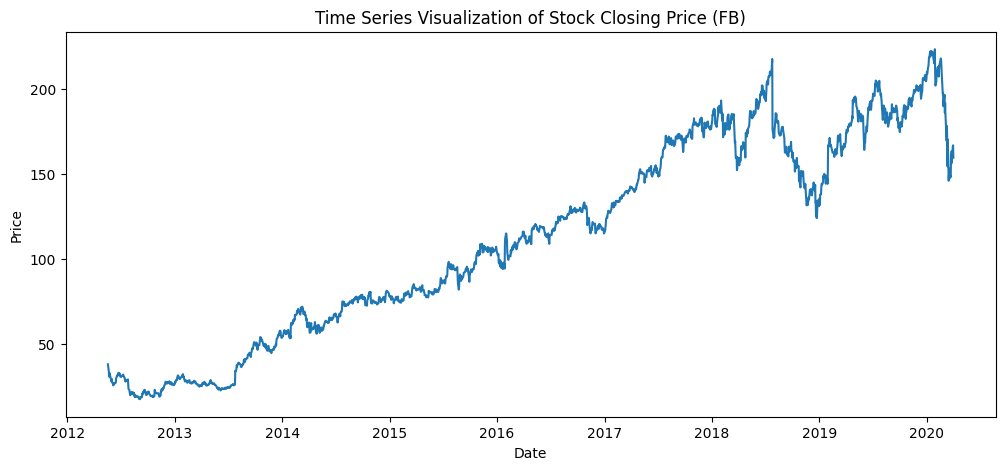

In [59]:
plt.figure(figsize=(12,5))
plt.plot(df1['Date'], df1['Close'])
plt.title('Time Series Visualization of Stock Closing Price (FB)')
plt.xlabel("Date")
plt.ylabel("Price")
plt.show()

Secara umum dapat dilihat harga saham FB mengalami peningkataan dari awal hingga akhir periode yaitu tahun 2012 hingga 2020. Namun, dapat dilihat juga bahwa harga saham FB masih sering naik turun dengan tajam, yang membuktikan bahwa situasi di pasar saham memang tidak stabil. Khususnya di tahun 2018-2020, harga saham turun cukup tajam sebelum mengalami kenaikan. Kemudian mengalami penurunan lagi di tahun 2020.

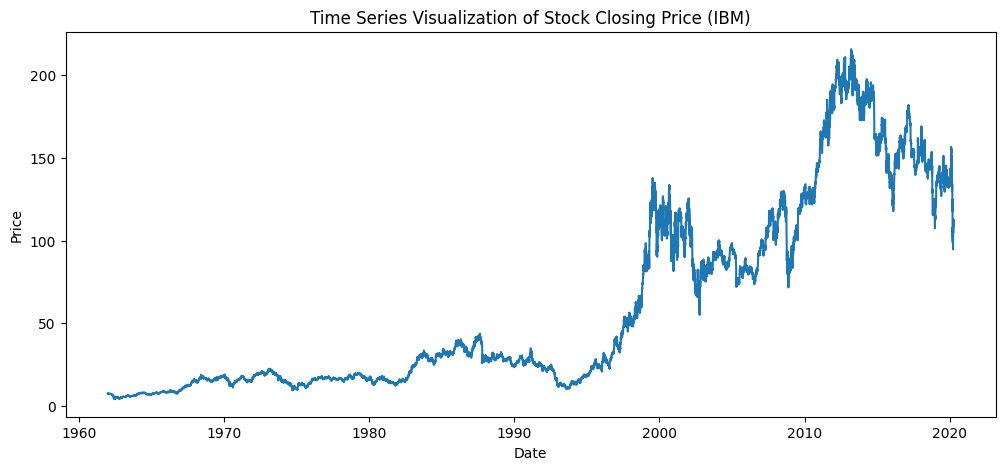

In [60]:
plt.figure(figsize=(12,5))
plt.plot(df2['Date'], df2['Close'])
plt.title('Time Series Visualization of Stock Closing Price (IBM)')
plt.xlabel("Date")
plt.ylabel("Price")
plt.show()

Pada periode awal yaitu tahun 1960an - 1990an, harga saham IBM relatif rendah dan meningkat secara bertahap. Kemudian sekitar tahun 1990an - 2000, terjadi kenaikan harga saham yang cukup signifikan. Lalu sekitar tahun 2000an - 2010an, harga saham kembali mengalami kenaikan hingga mencapai nilai tertinggi selama periode. Namun, setelah mencapai puncaknya, harga saham IBM cenderung menurun hingga akhir periode yaitu tahun 2020.

### Distribution Analysis

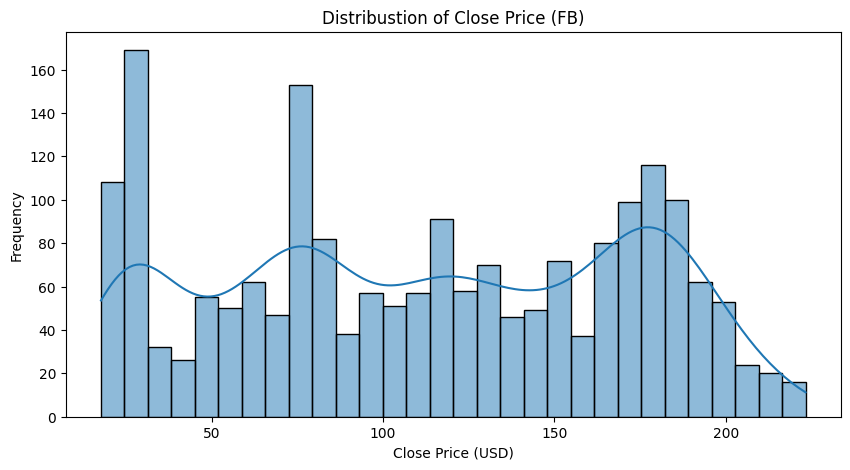

In [61]:
plt.figure(figsize=(10, 5))
sns.histplot(df1['Close'], kde=True, bins=30)
plt.title('Distribustion of Close Price (FB)')
plt.xlabel('Close Price (USD)')
plt.ylabel('Frequency')
plt.show()

Nilai Close Price tersebar cukup luas, yaitu berkisar antara sekitar 20 USD hingga 220 USD, yang menunjukkan bahwa harga saham Facebook (FB) mengalami perubahan yang signifikan selama periode pengamatan. Distribusi data tidak membentuk pola distribusi normal dan memiliki beberapa puncak (multimodal), yang menunjukkan bahwa terdapat beberapa rentang harga yang lebih sering muncul dibandingkan rentang harga lainnya.

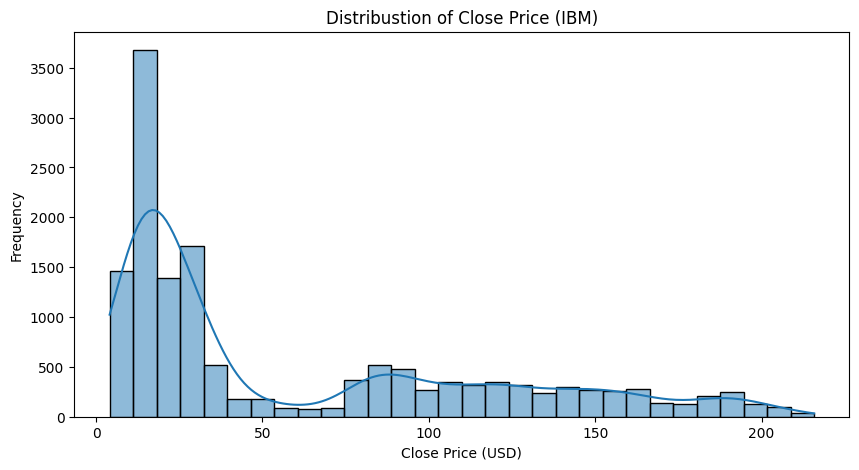

In [62]:
plt.figure(figsize=(10, 5))
sns.histplot(df2['Close'], kde=True, bins=30)
plt.title('Distribustion of Close Price (IBM)')
plt.xlabel('Close Price (USD)')
plt.ylabel('Frequency')
plt.show()

Nilai Close Price tersebar pada rentang sekitar 5 USD hingga lebih dari 220 USD, yang menunjukkan bahwa harga saham IBM mengalami perubahan yang cukup signifikan selama periode pengamatan. Distribusi data tidak mengikuti pola distribusi normal dan cenderung miring ke kanan (positively skewed), di mana sebagian besar observasi berada pada rentang harga 10–30 USD, sedangkan frekuensi observasi semakin menurun pada rentang harga yang lebih tinggi. Pola distribusi ini menunjukkan bahwa harga saham IBM lebih sering berada pada level harga rendah dibandingkan level harga tinggi.

### Outlier Analysis

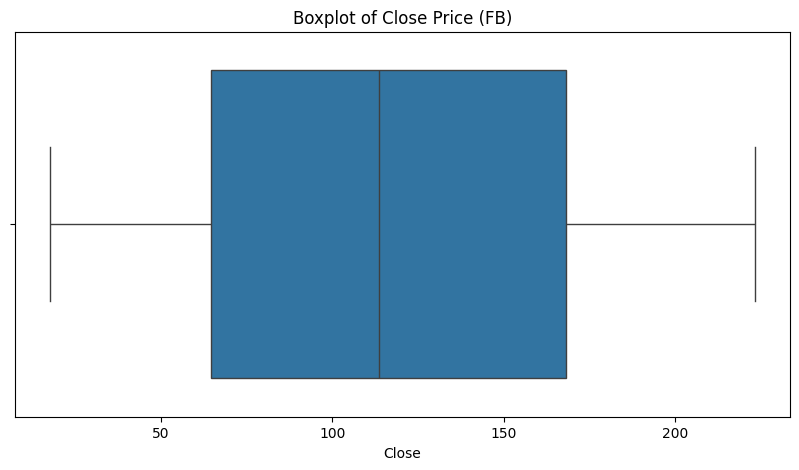

In [63]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df1['Close'])
plt.title('Boxplot of Close Price (FB)')
plt.show()

Boxplot menunjukkan bahwa distribusi harga penutupan saham Facebook (FB) memiliki rentang nilai yang cukup luas, dengan median berada di kisaran USD 110–120. Panjang kotak (Interquartile Range/IQR) yang relatif besar mengindikasikan bahwa 50% data berada dalam rentang harga yang lebar, sehingga mencerminkan adanya variasi harga saham selama periode pengamatan. Whisker pada kedua sisi memperlihatkan bahwa harga penutupan tersebar dari sekitar USD 20 hingga lebih dari USD 220 tanpa adanya titik observasi di luar batas whisker. Hal ini menunjukkan bahwa tidak terdapat outlier dalam data.

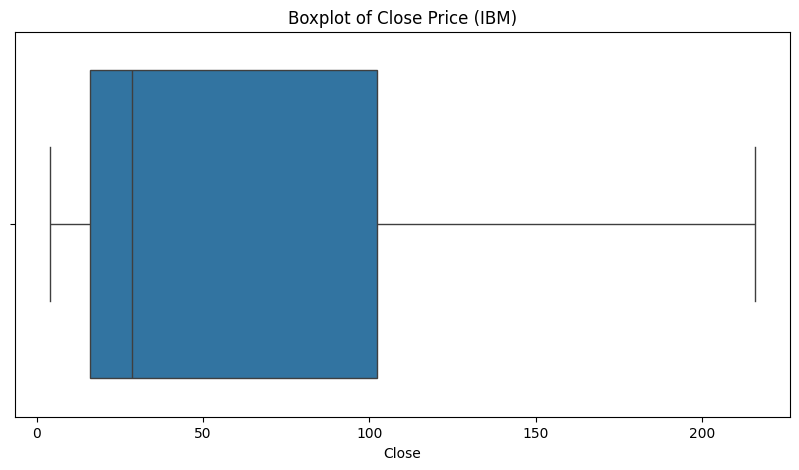

In [64]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df2['Close'])
plt.title('Boxplot of Close Price (IBM)')
plt.show()

  
Boxplot menunjukkan bahwa distribusi harga penutupan saham IBM memiliki median sekitar USD 30, dengan rentang interkuartil (IQR) yang cukup lebar, sehingga mengindikasikan adanya variasi harga selama periode pengamatan. Whisker bagian atas tampak lebih panjang dibandingkan whisker bagian bawah, yang menandakan penyebaran data pada harga tinggi lebih besar dibandingkan harga rendah. Pola ini konsisten dengan hasil analisis distribusi sebelumnya yang menunjukkan kecenderungan data miring ke kanan (positively skewed). Selain itu, tidak terlihat adanya titik observasi di luar batas whisker, sehingga dapat disimpulkan bahwa tidak terdapat outlier dalam data.

### Trend Analysis

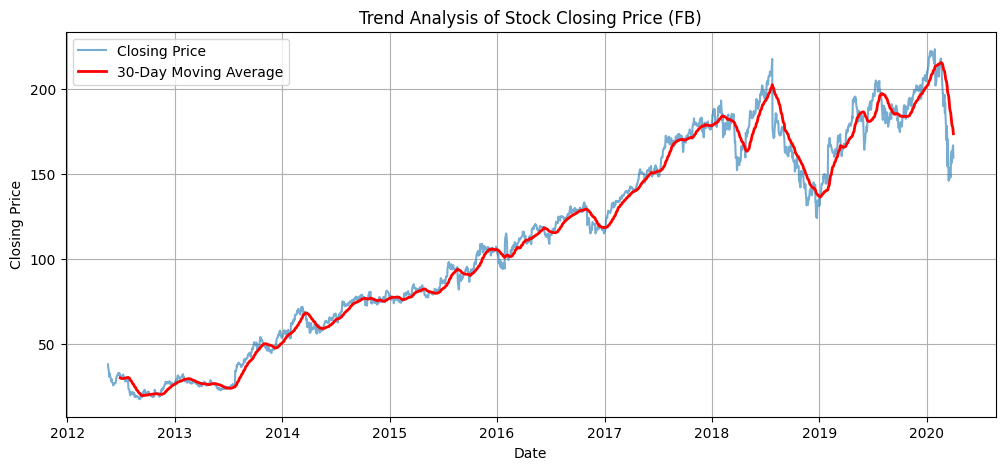

In [65]:
df1['MA30'] = df1['Close'].rolling(window=30).mean()

plt.figure(figsize=(12,5))
plt.plot(df1['Date'], df1['Close'], label='Closing Price', alpha=0.6)
plt.plot(df1['Date'], df1['MA30'], color='red', linewidth=2, label='30-Day Moving Average')

plt.title('Trend Analysis of Stock Closing Price (FB)')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.show()

Grafik menunjukkan bahwa Close Price saham FB cenderung naik sepanjang periode pengamatan. Garis MA30 mengikuti pergerakan harga harian dengan cukup baik dan membuat grafik jadi lebih halus, sehingga arah tren jangka panjang lebih mudah dilihat. Walaupun sempat ada penurunan, terutama sekitar tahun 2018–2019 dan menjelang akhir periode, secara keseluruhan tren harga tetap naik dibanding awal periode.

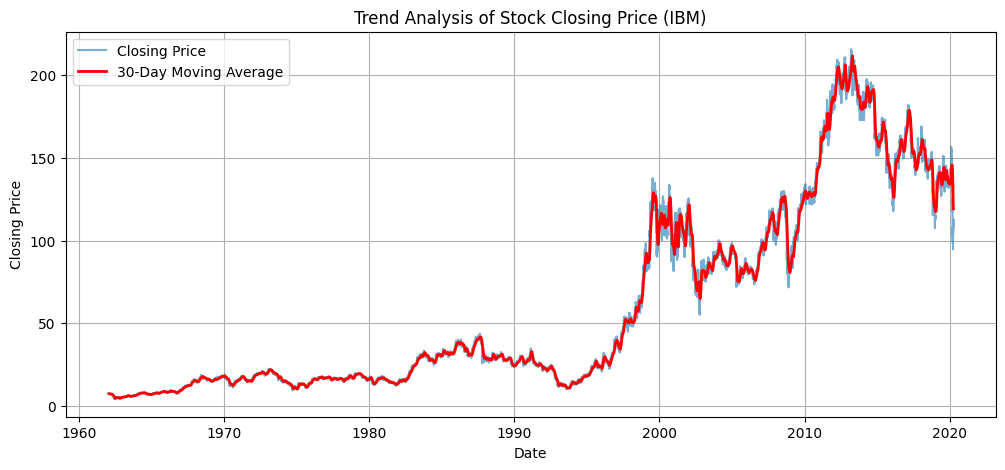

In [66]:
df2['MA30'] = df2['Close'].rolling(window=30).mean()

plt.figure(figsize=(12,5))

plt.plot(df2['Date'], df2['Close'], label='Closing Price', alpha=0.6)
plt.plot(df2['Date'], df2['MA30'], color='red', linewidth=2, label='30-Day Moving Average')

plt.title('Trend Analysis of Stock Closing Price (IBM)')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.show()

Grafik menunjukkan bahwa Close Price saham IBM mengalami perubahan tren yang dinamis sepanjang periode pengamatan. Garis MA30 mengikuti pergerakan harga dan membantu memperlihatkan tren jangka panjang. Terlihat tren naik bertahap sampai puncak sekitar 2013–2014, lalu cenderung turun dengan fluktuasi yang masih besar sampai akhir periode.

## Split Time Series

Data dipisahkan menjadi data training dan data testing. Dimana data test adalah data 1 tahun terakhir dan data train adalah semua data kecuali 1 tahun terakhir.

In [67]:
last_date1 = df1['Date'].max()
test_start1 = last_date1 - pd.DateOffset(years=1)

train_df1 = df1[df1['Date'] < test_start1]
test_df1 = df1[df1['Date'] >= test_start1]

print("Train:", train_df1.shape)
print("Test :", test_df1.shape)

Train: (1726, 3)
Test : (254, 3)


In [68]:
last_date2 = df2['Date'].max()
test_start2 = last_date2 - pd.DateOffset(years=1)

train_df2 = df2[df2['Date'] < test_start2]
test_df2 = df2[df2['Date'] >= test_start2]

print("Train:", train_df2.shape)
print("Test :", test_df2.shape)

Train: (14409, 3)
Test : (254, 3)


## Scaling

Normalisasi menggunakan MinMaxScaler sehingga seluruh nilai harga saham berada pada rentang 0-1. Proses ini diperlukan karena model LSTM lebih stabil kalau datanya sudah dinormalisasikan.

In [69]:
scaler_fb = MinMaxScaler()
scaler_ibm = MinMaxScaler()

train_scaled1 = scaler_fb.fit_transform(train_df1[['Close']])
test_scaled1 = scaler_fb.transform(test_df1[['Close']])

train_scaled2 = scaler_ibm.fit_transform(train_df2[['Close']])
test_scaled2 = scaler_ibm.transform(test_df2[['Close']])

## Windowing (Window Size = 5, Horizon = 1)

LSTM membutuhkan data dalam bentuk urutan (sequence). Oleh karena itu, data time series ini dubah menjadi dua bagian yaitu input dan output menggunakan window size = 5 dan horizon = 1

window size = 5 => setiap input ke model itu berisi 5 data terakhir (hari 1, hari 2, hari 3, hari 4, hari 5)

Horizon = 1 => target output yang diprediksi (harga saham di hari ke 6).

In [70]:
def create_sequences(data, window_size=5, horizon=1):

    X = []
    y = []

    for i in range(len(data) - window_size - horizon + 1):

        X.append(data[i:i + window_size])

        y.append(data[i + window_size:i + window_size + horizon])

    return np.array(X), np.array(y)

In [74]:
WINDOW_SIZE = 5
HORIZON = 1

# Training sequences for FB
X_train1, y_train1 = create_sequences(
    train_scaled1,
    window_size=WINDOW_SIZE,
    horizon=HORIZON
)

# Combine the last WINDOW_SIZE of training data with the test data for FB
test_history = np.concatenate([
        train_scaled1[-WINDOW_SIZE:],
        test_scaled1
    ],
    axis=0
)

# Test sequences for FB
X_test1, y_test1 = create_sequences(
    test_history,
    window_size=WINDOW_SIZE,
    horizon=HORIZON
)

print("FB Training:")
print("X_train1:", X_train1.shape)
print("y_train1:", y_train1.shape)

print("\nFB Testing:")
print("X_test1:", X_test1.shape)
print("y_test1:", y_test1.shape)

FB Training:
X_train1: (1721, 5, 1)
y_train1: (1721, 1, 1)

FB Testing:
X_test1: (254, 5, 1)
y_test1: (254, 1, 1)


In [75]:
WINDOW_SIZE = 5
HORIZON = 1

# Training sequences for IBM
X_train2, y_train2 = create_sequences(
    train_scaled2,
    window_size=WINDOW_SIZE,
    horizon=HORIZON
)

# Combine the last WINDOW_SIZE of training data with the test data for IBM
test_history = np.concatenate([
        train_scaled2[-WINDOW_SIZE:],
        test_scaled2
    ],
    axis=0
)

# Test sequences for IBM
X_test2, y_test2 = create_sequences(
    test_history,
    window_size=WINDOW_SIZE,
    horizon=HORIZON
)

print("IBM Training:")
print("X_train2:", X_train2.shape)
print("y_train2:", y_train2.shape)

print("\nIBM Testing:")
print("X_test2:", X_test2.shape)
print("y_test2:", y_test2.shape)

IBM Training:
X_train2: (14404, 5, 1)
y_train2: (14404, 1, 1)

IBM Testing:
X_test2: (254, 5, 1)
y_test2: (254, 1, 1)


## Split Train dan Validation

Berdasarkan instruksi soal yaitu data training dibagi menjadi 90% data train dan 10% data validation. Pembagian data ini dilakukan secara kronologis supaya urutan waktu tetap berurutan. Pendekatan ini juga membantu menghindari data leakage yang dapat terjadi apabila informasi dari periode yang lebih baru masuk ke proses pelatihan model.

In [76]:
split_index1 = int(len(X_train1) * 0.9)

X_train_final1 = X_train1[:split_index1]
X_val1 = X_train1[split_index1:]

y_train_final1 = y_train1[:split_index1]
y_val1 = y_train1[split_index1:]

print('X_train1 shape :', X_train_final1.shape)
print('X_val1 shape:', X_val1.shape)
print('X_test1 shape:', X_test1.shape)

print('\ny_train1 shape :', y_train_final1.shape)
print('y_val1 shape:', y_val1.shape)
print('y_test1 shape:', y_test1.shape)

X_train1 shape : (1548, 5, 1)
X_val1 shape: (173, 5, 1)
X_test1 shape: (254, 5, 1)

y_train1 shape : (1548, 1, 1)
y_val1 shape: (173, 1, 1)
y_test1 shape: (254, 1, 1)


In [77]:
split_index2 = int(len(X_train2) * 0.9)

X_train_final2 = X_train2[:split_index2]
X_val2 = X_train2[split_index2:]

y_train_final2 = y_train2[:split_index2]
y_val2 = y_train2[split_index2:]

print('X_train2 shape :', X_train_final2.shape)
print('X_val2 shape:', X_val2.shape)
print('X_test1 shape:', X_test2.shape)

print('\ny_train2 shape :', y_train_final2.shape)
print('y_val2 shape:', y_val2.shape)
print('y_test2 shape:', y_test2.shape)

X_train2 shape : (12963, 5, 1)
X_val2 shape: (1441, 5, 1)
X_test1 shape: (254, 5, 1)

y_train2 shape : (12963, 1, 1)
y_val2 shape: (1441, 1, 1)
y_test2 shape: (254, 1, 1)


## Persistence baseline (FB)

In [78]:
y_pred_persistence1 = X_test1[:, -1, 0]

print("Persistence predictions:", y_pred_persistence1.shape)
print("Actual targets:", y_test1.shape)

Persistence predictions: (254,)
Actual targets: (254, 1, 1)


In [79]:
# Convert scaled values back to the original price scale
y_test_actual1 = scaler_fb.inverse_transform(y_test1.reshape(-1, 1)).ravel()
y_pred_persistence_actual1 = scaler_fb.inverse_transform(y_pred_persistence1.reshape(-1, 1)).ravel()

# Evaluasi metrik untuk baseline persistence
rmse_persistence1 = np.sqrt(
    mean_squared_error(
        y_test_actual1,
        y_pred_persistence_actual1
    )
)

mae_persistence1 = mean_absolute_error(
    y_test_actual1,
    y_pred_persistence_actual1
)

mape_persistence1 = mean_absolute_percentage_error(
    y_test_actual1,
    y_pred_persistence_actual1
) * 100

print("FB Persistence Baseline")
print(f"RMSE: {rmse_persistence1:.4f}")
print(f"MAE:  {mae_persistence1:.4f}")
print(f"MAPE: {mape_persistence1:.2f}%")

FB Persistence Baseline
RMSE: 4.1735
MAE:  2.8427
MAPE: 1.55%


## Persistence baseline (IBM)

In [80]:
y_pred_persistence2 = X_test2[:, -1, 0]

print("Persistence predictions:", y_pred_persistence2.shape)
print("Actual targets:", y_test2.shape)

Persistence predictions: (254,)
Actual targets: (254, 1, 1)


In [81]:
# Convert scaled values back to the original price scale
y_test_actual2 = scaler_ibm.inverse_transform(y_test2.reshape(-1, 1)).ravel()
y_pred_persistence_actual2 = scaler_ibm.inverse_transform(y_pred_persistence2.reshape(-1, 1)).ravel()

# Evaluasi metrik untuk baseline persistence
rmse_persistence2 = np.sqrt(
    mean_squared_error(
        y_test_actual2,
        y_pred_persistence_actual2
    )
)

mae_persistence2 = mean_absolute_error(
    y_test_actual2,
    y_pred_persistence_actual2
)

mape_persistence2 = mean_absolute_percentage_error(
    y_test_actual2,
    y_pred_persistence_actual2
) * 100

print("IBM Persistence Baseline")
print(f"RMSE: {rmse_persistence2:.4f}")
print(f"MAE:  {mae_persistence2:.4f}")
print(f"MAPE: {mape_persistence2:.2f}%")

IBM Persistence Baseline
RMSE: 2.6892
MAE:  1.7202
MAPE: 1.33%


## Baseline LSTM (FB)

Baseline model untuk memprediksi Close Price saham FB berdasarkan 5 hari sebelumnya (window size = 5).

LSTM layer:
- 50 unit = 50 memory cells yang digunakan untuk mempelajari pola temporal dari data time series FB.
- activation = relu, membantu model mempelajari hubungan non-linear.
- input shape = (5, 1) yang diperoleh dari X_train_final. Artinya 5 time steps (window size = 5) dan 1 feature (Close Price).

Dense layer:
- 1 neuron (Perceptron) = memprediksi satu nilai Close Price (horizon = 1).

In [82]:
baseline_model1 = Sequential([

    LSTM(
        units=50,
        activation='relu',
        input_shape=(X_train_final1.shape[1],
                     X_train_final1.shape[2])
    ),
    Dense(units=1)
])

# Compile model
baseline_model1.compile(
    optimizer='sgd',
    loss='mse',
    metrics=['mae']
)

baseline_model1.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 50)                10400     
                                                                 
 dense (Dense)               (None, 1)                 51        
                                                                 
Total params: 10451 (40.82 KB)
Trainable params: 10451 (40.82 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### Training Model

Training model menggunakan data train dan evaluasi performa model menggunakan validation set.

50 epoch agar model memiliki kesempatan cukup untuk mempelajari pola pada data tanpa membuat proses train terlalu lama.

In [83]:
history_baseline1 = baseline_model1.fit(

    X_train_final1, y_train_final1,
    validation_data=(
        X_val1,
        y_val1
    ),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50


49/49 [==============================] - 1s 8ms/step - loss: 0.1019 - mae: 0.2521 - val_loss: 0.1431 - val_mae: 0.3716
Epoch 2/50
49/49 [==============================] - 0s 2ms/step - loss: 0.0511 - mae: 0.1849 - val_loss: 0.0841 - val_mae: 0.2818
Epoch 3/50
49/49 [==============================] - 0s 2ms/step - loss: 0.0434 - mae: 0.1759 - val_loss: 0.0681 - val_mae: 0.2524
Epoch 4/50
49/49 [==============================] - 0s 3ms/step - loss: 0.0387 - mae: 0.1664 - val_loss: 0.0592 - val_mae: 0.2346
Epoch 5/50
49/49 [==============================] - 0s 2ms/step - loss: 0.0347 - mae: 0.1572 - val_loss: 0.0515 - val_mae: 0.2186
Epoch 6/50
49/49 [==============================] - 0s 2ms/step - loss: 0.0316 - mae: 0.1502 - val_loss: 0.0455 - val_mae: 0.2052
Epoch 7/50
49/49 [==============================] - 0s 3ms/step - loss: 0.0290 - mae: 0.1442 - val_loss: 0.0407 - val_mae: 0.1939
Epoch 8/50
49/49 [==============================] - 0s 3ms/step - loss: 0.0266 - mae: 0.

### Visualisasi Training Loss vs Validation Loss

Membandingkan training loss dan validation loss, untuk dapat mengetahui apakah model berhasil belajar dengan baik atau mengalami underfitting maupun overfitting.

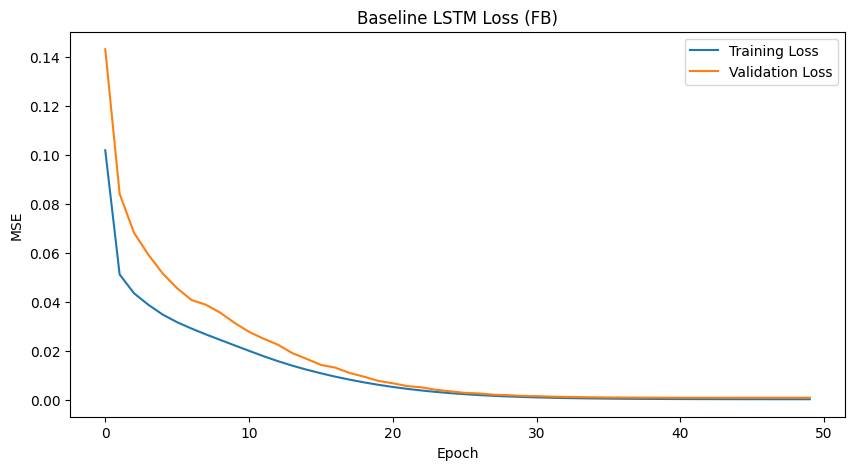

In [84]:
plt.figure(figsize=(10,5))
plt.plot(history_baseline1.history['loss'], label='Training Loss')
plt.plot(history_baseline1.history['val_loss'], label='Validation Loss')
plt.title('Baseline LSTM Loss (FB)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

Grafik menunjukkan bahwa training loss dan validation loss mengalami penurunan yang sangat cepat pada beberapa epoch pertama, kemudian keduanya stabil hingga akhir proses training. Hal ini menunjukkan bahwa model berhasil mempelajari pola pada data training dan telah mencapai kondisi konvergen. Selain itu, kedua kurva memiliki pola yang relatif serupa tanpa adanya peningkatan validation loss yang signifikan, sehingga tidak terdapat indikasi overfitting yang kuat berdasarkan grafik training.

### Gap Analysis

Mengukur selisih antara training loss dan validation loss untuk mengetahui kemampuan generalisasi model.

In [85]:
train_loss1 = history_baseline1.history['loss'][-1]
val_loss1 = history_baseline1.history['val_loss'][-1]

gap1 = val_loss1 - train_loss1
gap_ratio1 = (gap1 / train_loss1) * 100

print(f"Train Loss      : {train_loss1:.6f}")
print(f"Validation Loss : {val_loss1:.6f}")
print(f"Loss Gap        : {gap1:.6f}")
print(f"Gap Ratio       : {gap_ratio1:.2f}%")

Train Loss      : 0.000142
Validation Loss : 0.000770
Loss Gap        : 0.000628
Gap Ratio       : 440.52%


Walaupun gap ratio kelihatan besar, itu disebabkan oleh nilai train loss yang sangat kecil, jadi persentase gap jadi kelihatan besar dan melonjak. Tetapi jika dilihat grafiknya, validation loss tetap rendah dan stabil sepanjang proses training. Artinya, model masih bisa generalisasi dengan cukup baik, meskipun ada sedikit beda performa antara data training dan validation.

### Prediction on Test Set

Menggunakan baseline model untuk memprediksi harga saham pada data testing.

In [86]:
y_pred1 = baseline_model1.predict(X_test1)

y_test_actual1 = scaler_fb.inverse_transform(y_test1.reshape(-1,1))
y_pred_actual1 = scaler_fb.inverse_transform(y_pred1)

8/8 [==============================] - 0s 1ms/step


Sebelumnya data sudah dinormalisasi menggunakan MinMaxScaler sehingga prediksi model berada pada skala 0–1. Oleh karena itu, dilakukan inverse transform agar hasil prediksi kembali ke satuan harga saham asli (USD).

### Compare Actual vs Predicted

Membandingkan nilai aktual dengan hasil prediksi model pada data testing. Semakin kecil selisihnya maka semakin baik performa modelnya.

In [87]:
comparison1 = pd.DataFrame({
    'Actual Price': y_test_actual1.flatten(),
    'Predicted Price': y_pred_actual1.flatten()
})

comparison1['Difference'] = (comparison1['Actual Price'] - comparison1['Predicted Price'])
comparison1.head(10)

,Actual Price,Predicted Price,Difference
0,168.699997,166.534943,2.165054
1,174.199997,167.283829,6.916168
2,173.539993,169.510010,4.029984
3,176.020004,171.160385,4.859619
4,175.720001,173.179337,2.540665
5,174.929993,174.483459,0.446533
6,177.580002,175.021255,2.558746
7,177.820007,175.860550,1.959457
8,177.509995,176.618881,0.891113
9,179.100006,176.918060,2.181946


Tabel perbandingan menunjukkan bahwa nilai prediksi model cukup dekat dengan nilai aktual. Sebagian besar selisih prediksi berada pada kisaran yang relatif kecil, yaitu sekitar 0 hingga 6 USD, sehingga menunjukkan bahwa model mampu memprediksi harga penutupan saham dengan cukup akurat pada sebagian besar observasi.

### Visualisasi Actual vs Prediction

Mengevaluasi apakah model mampu mengikuti pola perubahan harga saham pada data testing.

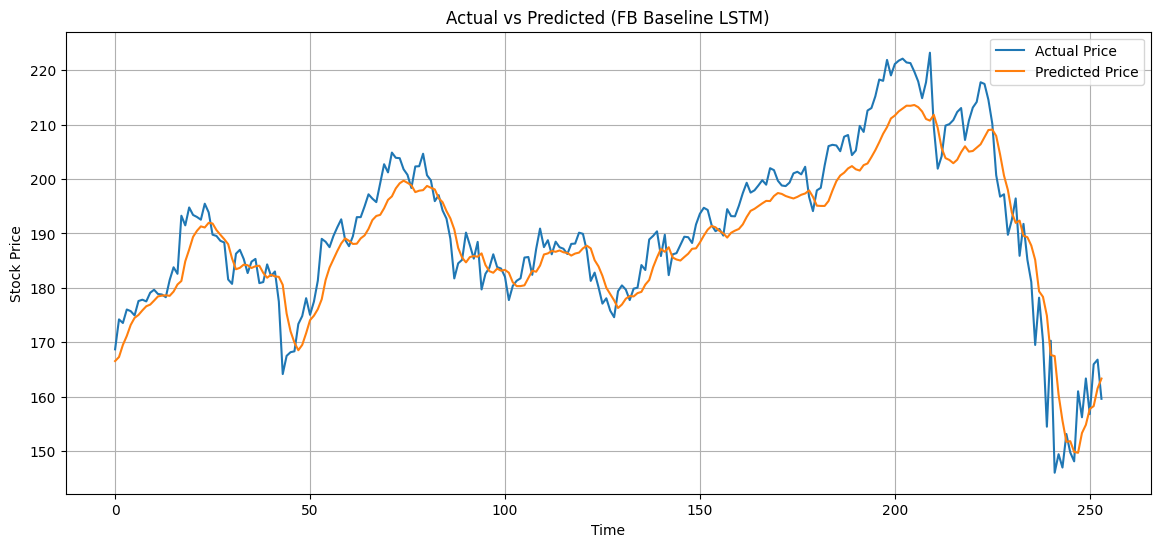

In [88]:
plt.figure(figsize=(14,6))
plt.plot(y_test_actual1,label='Actual Price')
plt.plot(y_pred_actual1, label='Predicted Price')
plt.title('Actual vs Predicted (FB Baseline LSTM)')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.grid(True)
plt.show()

Grafik menunjukkan bahwa garis prediksi mengikuti pola pergerakan harga saham aktual dengan cukup baik. Model berhasil menangkap tren kenaikan maupun penurunan harga selama periode pengujian. Meskipun terdapat sedikit perbedaan pada beberapa titik, terutama ketika terjadi perubahan harga yang lebih tajam, secara keseluruhan model mampu merepresentasikan pola historis harga saham dengan baik.

### Evaluasi Metric

Mengukur tingkat kesalahan prediksi model menggunakan tiga metrik evaluasi regresi yaitu rmse, mae, dan mape.

In [89]:
rmse1 = np.sqrt(mean_squared_error(y_test_actual1, y_pred_actual1))
mae1 = mean_absolute_error(y_test_actual1, y_pred_actual1)
mape1 = np.mean(np.abs((y_test_actual1 - y_pred_actual1)/ y_test_actual1)) * 100

print('Evaluasi Baseline LSTM (FB)')
print(f"RMSE : {rmse1:.4f}")
print(f"MAE  : {mae1:.4f}")
print(f"MAPE : {mape1:.4f}%")

Evaluasi Baseline LSTM (FB)
RMSE : 5.4912
MAE  : 4.3111
MAPE : 2.2657%


Hasil evaluasi menunjukkan nilai RMSE sebesar 5.4912, MAE sebesar 4.3111, dan MAPE sebesar 2.2657%. Nilai MAE menunjukkan bahwa rata-rata selisih antara harga aktual dan hasil prediksi sekitar 4.31 USD, sedangkan nilai MAPE sebesar 2.26% menunjukkan bahwa tingkat kesalahan prediksi model relatif rendah. Secara keseluruhan, model baseline memiliki performa yang baik dalam melakukan prediksi harga saham Facebook.


## Baseline LSTM (IBM)

In [90]:
baseline_model2 = Sequential([

    LSTM(
        units=50,
        activation='relu',
        input_shape=(X_train_final2.shape[1],
                     X_train_final2.shape[2])
    ),
    Dense(units=1)
])

#Compile model
baseline_model2.compile(
    optimizer=Adam(),
    loss='mse',
    metrics=['mae']
)

baseline_model2.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_1 (LSTM)               (None, 50)                10400     
                                                                 
 dense_1 (Dense)             (None, 1)                 51        
                                                                 
Total params: 10451 (40.82 KB)
Trainable params: 10451 (40.82 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### Training Model

In [91]:
history_baseline2 = baseline_model2.fit(

    X_train_final2,y_train_final2,
    validation_data=(
        X_val2,
        y_val2
    ),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
406/406 [==============================] - 2s 2ms/step - loss: 0.0046 - mae: 0.0209 - val_loss: 2.0797e-04 - val_mae: 0.0112
Epoch 2/50
406/406 [==============================] - 1s 2ms/step - loss: 6.3993e-05 - mae: 0.0046 - val_loss: 1.9139e-04 - val_mae: 0.0105
Epoch 3/50
406/406 [==============================] - 1s 2ms/step - loss: 6.0538e-05 - mae: 0.0043 - val_loss: 1.7935e-04 - val_mae: 0.0100
Epoch 4/50
406/406 [==============================] - 1s 2ms/step - loss: 5.9794e-05 - mae: 0.0044 - val_loss: 1.6673e-04 - val_mae: 0.0093
Epoch 5/50
406/406 [==============================] - 1s 2ms/step - loss: 6.0463e-05 - mae: 0.0044 - val_loss: 1.8776e-04 - val_mae: 0.0099
Epoch 6/50
406/406 [==============================] - 1s 2ms/step - loss: 5.9924e-05 - mae: 0.0046 - val_loss: 2.7847e-04 - val_mae: 0.0139
Epoch 7/50
406/406 [==============================] - 1s 2ms/step - loss: 5.9662e-05 - mae: 0.0045 - val_loss: 1.5462e-04 - val_mae: 0.0089
Epoch 8/50
406/406 [====

### Visualisasi Traing Loss vs Validation Loss

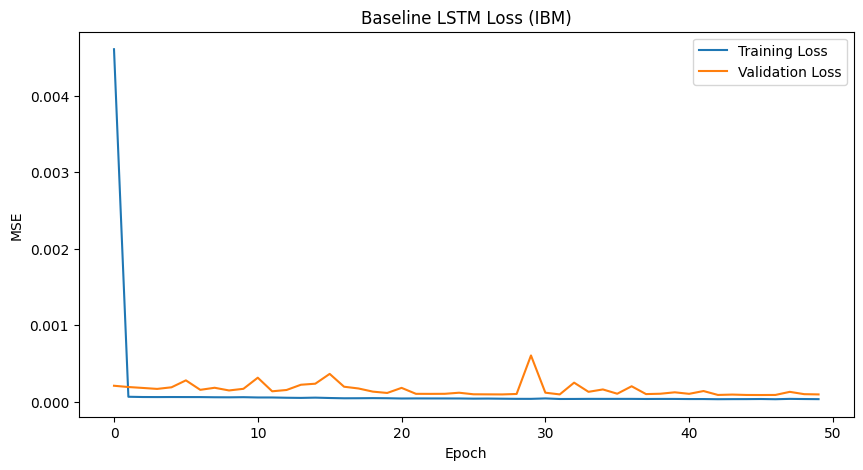

In [92]:
plt.figure(figsize=(10,5))
plt.plot(history_baseline2.history['loss'], label='Training Loss')
plt.plot(history_baseline2.history['val_loss'], label='Validation Loss')
plt.title('Baseline LSTM Loss (IBM)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

Grafik Baseline LSTM Loss (IBM) menunjukkan bahwa training loss mengalami penurunan yang sangat cepat pada epoch pertama, kemudian stabil pada nilai yang sangat kecil hingga akhir proses pelatihan. Validation loss juga berada pada nilai yang rendah dan memiliki pola yang relatif stabil serta mengikuti training loss. Hal ini menunjukkan bahwa model berhasil mempelajari pola data saham IBM dengan baik, telah mencapai kondisi konvergen, dan tidak menunjukkan indikasi overfitting yang signifikan karena selisih antara training loss dan validation loss sangat kecil.

### Gap Analysis

In [93]:
train_loss2 = history_baseline2.history['loss'][-1]
val_loss2 = history_baseline2.history['val_loss'][-1]

gap2 = val_loss2 - train_loss2
gap_ratio2 = (gap2 / train_loss2) * 100

print(f"Train Loss      : {train_loss2:.6f}")
print(f"Validation Loss : {val_loss2:.6f}")
print(f"Loss Gap        : {gap2:.6f}")
print(f"Gap Ratio       : {gap_ratio2:.2f}%")

Train Loss      : 0.000033
Validation Loss : 0.000095
Loss Gap        : 0.000062
Gap Ratio       : 189.20%


Persentase gap yang tinggi disebabkan oleh nilai training loss yang sangat kecil sehingga menghasilkan gap ratio yang besar secara matematis. Namun, berdasarkan grafik training, validation loss tetap rendah dan stabil, sehingga model masih memiliki kemampuan generalisasi yang cukup baik dan tidak menunjukkan indikasi overfitting yang signifikan.

### Prediction on Test Set

In [94]:
y_pred2 = baseline_model2.predict(X_test2)

y_test_actual2 = scaler_ibm.inverse_transform(y_test2.reshape(-1,1))
y_pred_actual2 = scaler_ibm.inverse_transform(y_pred2)


8/8 [==============================] - 0s 1ms/step


Sebelumnya data sudah dinormalisasi menggunakan MinMaxScaler sehingga prediksi model berada pada skala 0–1. Oleh karena itu, dilakukan inverse transform agar hasil prediksi kembali ke satuan harga saham asli (USD).

### Compare Actual vs Predicted

In [95]:
comparison2 = pd.DataFrame({
    'Actual Price': y_test_actual2.flatten(),
    'Predicted Price': y_pred_actual2.flatten()
})

comparison2['Difference'] = (comparison2['Actual Price'] - comparison2['Predicted Price'])
comparison2.head(10)

,Actual Price,Predicted Price,Difference
0,143.300003,140.486649,2.813354
1,143.000000,142.538452,0.461548
2,143.630005,142.558487,1.071518
3,142.779999,143.021561,-0.241562
4,143.279999,142.383957,0.896042
5,143.389999,142.695770,0.694229
6,142.110001,142.878906,-0.768906
7,143.020004,141.770996,1.249008
8,143.779999,142.382645,1.397354
9,144.350006,143.198517,1.151489


Hasil prediksi menunjukkan bahwa model mampu menghasilkan nilai yang cukup dekat dengan harga saham aktual. Perbedaan antara nilai aktual dan prediksi relatif kecil pada sebagian besar observasi, sehingga menunjukkan bahwa model berhasil mempelajari pola historis harga saham IBM dengan baik.

### Visualisasi Actual vs Predicted

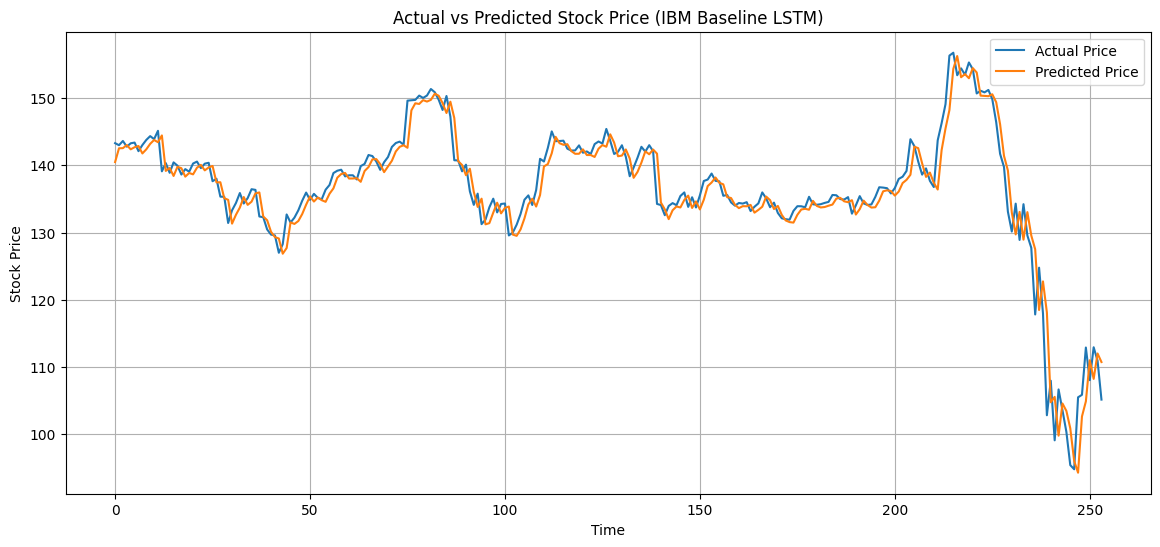

In [96]:
plt.figure(figsize=(14,6))
plt.plot(y_test_actual2,label='Actual Price')
plt.plot(y_pred_actual2, label='Predicted Price')
plt.title('Actual vs Predicted Stock Price (IBM Baseline LSTM)')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.grid(True)
plt.show()

Grafik perbandingan Actual Price dan Predicted Price menunjukkan bahwa hasil prediksi model hampir selalu mengikuti pergerakan harga saham IBM yang sebenarnya. Garis prediksi terlihat sangat berdekatan dengan garis harga aktual, baik saat terjadi kenaikan, penurunan, maupun fluktuasi harga yang cukup tajam. Meskipun terdapat sedikit perbedaan pada beberapa titik, secara keseluruhan model mampu menangkap pola perubahan harga dengan baik. Hal ini menunjukkan bahwa Baseline LSTM memiliki kemampuan yang baik dalam melakukan prediksi time series pada data saham IBM dan menghasilkan prediksi yang mendekati nilai aktual.

### Evaluasi Metric

In [97]:
rmse2 = np.sqrt(mean_squared_error(y_test_actual2, y_pred_actual2))
mae2 = mean_absolute_error(y_test_actual2, y_pred_actual2)
mape2 = np.mean(np.abs((y_test_actual2 - y_pred_actual2)/ y_test_actual2)) * 100

print('Evaluasi Baseline LSTM (IBM)')
print(f"RMSE : {rmse2:.4f}")
print(f"MAE  : {mae2:.4f}")
print(f"MAPE : {mape2:.4f}%")

Evaluasi Baseline LSTM (IBM)
RMSE : 2.6634
MAE  : 1.7815
MAPE : 1.3657%


Hasil evaluasi menunjukkan nilai RMSE sebesar 2.6634, MAE sebesar 1.7815, dan MAPE sebesar 1.3657%. Nilai MAE menunjukkan bahwa rata-rata kesalahan prediksi sekitar 1.74 USD, sedangkan nilai MAPE sebesar 1.36% menunjukkan bahwa tingkat kesalahan prediksi model sangat rendah. Secara keseluruhan, model baseline memiliki performa yang baik dalam memprediksi harga saham IBM.

Kesimpulan:

Berdasarkan hasil evaluasi model baseline untuk kedua data times series (FB dan IBM), model telah mampu mengikuti pola pergerakan harga saham dengan cukup baik. Namun, masih terdapat selisih antara nilai aktual dan hasil prediksi pada beberapa periode, terutama ketika terjadi perubahan harga yang cukup tajam. Oleh karena itu, dilakukan modifikasi arsitektur untuk meningkatkan kemampuan model dalam mempelajari pola temporal yang lebih kompleks dan meningkatkan kemampuan generalisasi.

## Modified Model (FB)

In [204]:
modified_model1 = Sequential([
    LSTM(
        units=64,
        activation='tanh',
        input_shape=(
            X_train_final1.shape[1],
            X_train_final1.shape[2]
        )
    ),

    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(1)
])

# Compile model
modified_model1.compile(
    optimizer= Adam(
        learning_rate = 0.001
    ),
    loss='mse',
    metrics=['mae']
)

# Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    min_delta=0.00001
)

modified_model1.summary()

Model: "sequential_15"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_17 (LSTM)              (None, 64)                16896     
                                                                 
 dropout_13 (Dropout)        (None, 64)                0         
                                                                 
 dense_27 (Dense)            (None, 16)                1040      
                                                                 
 dense_28 (Dense)            (None, 1)                 17        
                                                                 
Total params: 17953 (70.13 KB)
Trainable params: 17953 (70.13 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### Training model

Jumlah epoch menjadi 50 supaya model memiliki kesempatan yang lebih besar untuk model mempelajari pola data harga saham secara optimal. Namun, disini saya juga menggunakan EarlyStopping sehingga proses training akan berhenti secara otomatis ketika validation loss tidak membaik dalam beberapa epoch berturut-turut. Selain itu, dapat mencegah overfitting dan mengurangi waktu proses training.

Batch size dari 32 menjadi 16 agar model melakukan pembaruan bobot lebih sering dalam setiap epoch. Hal ini membantu model mempelajari pola data secara lebih detail dan meningkatkan akurasi prediksi, meskipun training menjadi sedikit lebih lama.

In [205]:
history_modified1 = modified_model1.fit(

    X_train_final1, y_train_final1,
    validation_data=(
        X_val1,
        y_val1
    ),
    epochs=50,
    batch_size=16,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

Epoch 1/50
97/97 [==============================] - 2s 6ms/step - loss: 0.0017 - mae: 0.0315 - val_loss: 0.0019 - val_mae: 0.0358
Epoch 2/50
97/97 [==============================] - 0s 2ms/step - loss: 0.0026 - mae: 0.0402 - val_loss: 0.0053 - val_mae: 0.0667
Epoch 3/50
97/97 [==============================] - 0s 2ms/step - loss: 0.0028 - mae: 0.0400 - val_loss: 9.3145e-04 - val_mae: 0.0199
Epoch 4/50
97/97 [==============================] - 0s 2ms/step - loss: 0.0015 - mae: 0.0288 - val_loss: 0.0012 - val_mae: 0.0229
Epoch 5/50
97/97 [==============================] - 0s 3ms/step - loss: 9.2448e-04 - mae: 0.0219 - val_loss: 0.0014 - val_mae: 0.0270
Epoch 6/50
97/97 [==============================] - 0s 2ms/step - loss: 9.8832e-04 - mae: 0.0229 - val_loss: 0.0011 - val_mae: 0.0222
Epoch 7/50
97/97 [==============================] - 0s 2ms/step - loss: 7.6358e-04 - mae: 0.0197 - val_loss: 8.5327e-04 - val_mae: 0.0193
Epoch 8/50
97/97 [==============================] - 0s 3ms/step - loss

### Visualisasi Train Loss vs Val Loss

Untuk melihat apakah modifikasi arsitektur berhasil meningkatkan proses training dan mengurangi risiko overfitting dibandingkan model baseline.

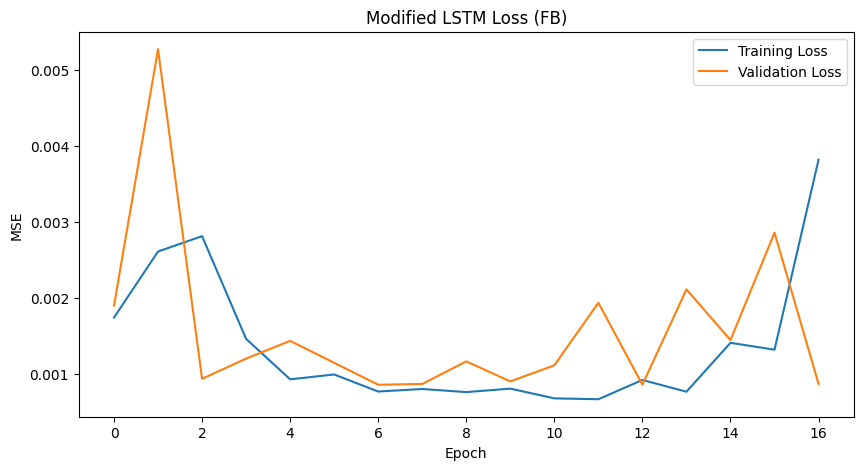

In [206]:
plt.figure(figsize=(10,5))
plt.plot(history_modified1.history['loss'], label='Training Loss')
plt.plot(history_modified1.history['val_loss'], label='Validation Loss')
plt.title('Modified LSTM Loss (FB)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

### Gap Analysis

Mengukur selisih antara train loss dan val loss untuk mengevaluasi kemampuan generalisasi model setelah dilakukan modifikasi arsitektur.

In [207]:
# Evaluasi model menggunakan bobot yang saat ini tersimpan
modified_train_loss1, modified_train_mae1 = modified_model1.evaluate(
    X_train_final1,
    y_train_final1,
    verbose=0
)

modified_val_loss1, modified_val_mae1 = modified_model1.evaluate(
    X_val1,
    y_val1,
    verbose=0
)

# Gap analysis
modified_loss_gap1 = modified_val_loss1 - modified_train_loss1

modified_gap_ratio1 = (
    modified_loss_gap1 / modified_train_loss1
) * 100

print("Gap Analysis - FB Modified LSTM")
print(f"Training Loss   : {modified_train_loss1:.6f}")
print(f"Validation Loss : {modified_val_loss1:.6f}")
print(f"Loss Gap        : {modified_loss_gap1:.6f}")
print(f"Gap Ratio       : {modified_gap_ratio1:.2f}%")

Gap Analysis - FB Modified LSTM
Training Loss   : 0.000567
Validation Loss : 0.000853
Loss Gap        : 0.000286
Gap Ratio       : 50.42%


### Prediction on Test Set

Menggunakan model yang telah dimodifikasi untuk melakukan prediksi harga saham pada data testing.

In [208]:
y_pred_modified1 = modified_model1.predict(X_test1)

y_test_actual_modified1 = scaler_fb.inverse_transform(y_test1.reshape(-1,1))
y_pred_actual_modified1 = scaler_fb.inverse_transform(y_pred_modified1)

8/8 [==============================] - 0s 2ms/step


Output model masih berada pada rentang 0–1 karena sebelumnya dinormalisasikan menggunakan MinMaxScaler, sehingga perlu dilakukan inverse transform agar hasil prediksi kembali ke satuan harga saham sebenarnya (USD).

### Compare Actual vs Predicted

Membandingkan nilai aktual dengan hasil prediksi model yang telah dimodifikasi.

In [209]:
comparison_modified1 = pd.DataFrame({
    'Actual Price': y_test_actual_modified1.flatten(),
    'Predicted Price': y_pred_actual_modified1.flatten()
})

comparison_modified1['Difference'] = (comparison_modified1['Actual Price'] - comparison_modified1['Predicted Price'])
comparison_modified1.head(10)

,Actual Price,Predicted Price,Difference
0,168.699997,165.046509,3.653488
1,174.199997,165.620270,8.579727
2,173.539993,167.526291,6.013702
3,176.020004,169.305511,6.714493
4,175.720001,171.313354,4.406647
5,174.929993,172.722351,2.207642
6,177.580002,173.360352,4.219650
7,177.820007,174.071014,3.748993
8,177.509995,174.805481,2.704514
9,179.100006,175.198822,3.901184


### Visualisasi Actual vs Predicted

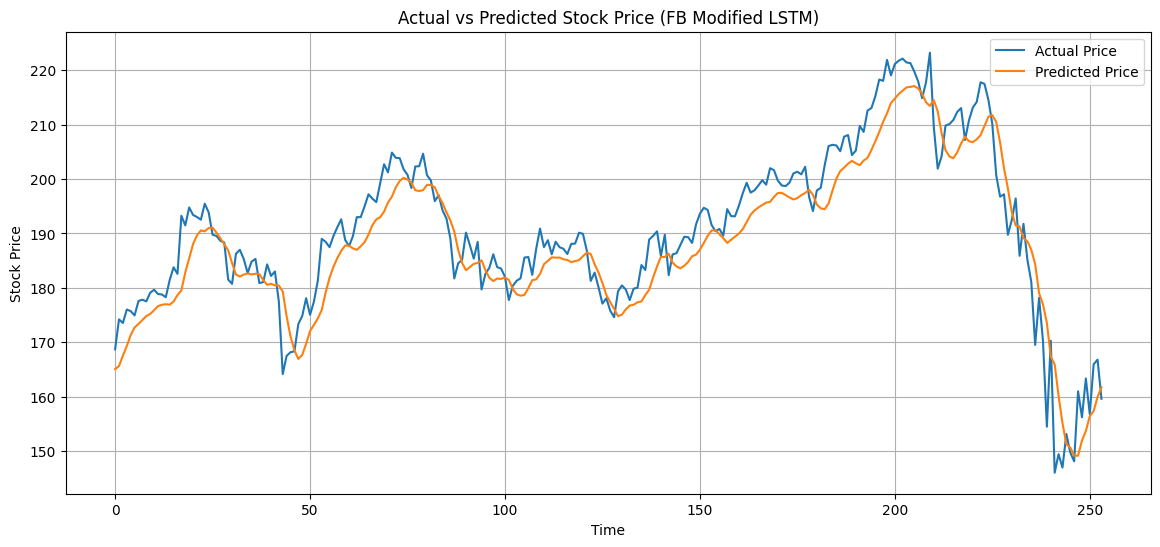

In [210]:
plt.figure(figsize=(14,6))
plt.plot(y_test_actual_modified1, label='Actual Price')
plt.plot(y_pred_actual_modified1, label='Predicted Price')
plt.title('Actual vs Predicted Stock Price (FB Modified LSTM)')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.grid(True)
plt.show()

Grafik Actual vs Predicted Stock Price menunjukkan bahwa garis prediksi hampir selalu mengikuti pola pergerakan harga saham yang sebenarnya. Model mampu menangkap tren kenaikan, penurunan, maupun fluktuasi harga sepanjang periode pengujian. Walaupun terdapat sedikit perbedaan pada beberapa titik, terutama ketika terjadi perubahan harga yang cukup tajam, garis prediksi tetap berada sangat dekat dengan garis aktual. Hal ini menunjukkan bahwa Modified LSTM memiliki kemampuan yang baik dalam mempelajari pola historis data sehingga mampu menghasilkan prediksi harga saham yang mendekati nilai sebenarnya.

### Evaluasi Metric

In [211]:
rmse1_modified = np.sqrt(mean_squared_error(y_test_actual_modified1, y_pred_actual_modified1))
mae1_modified = mean_absolute_error(y_test_actual_modified1, y_pred_actual_modified1)
mape1_modified = np.mean(np.abs((y_test_actual_modified1 - y_pred_actual_modified1)/ y_test_actual_modified1)) * 100

print('Evaluasi Modified LSTM (FB)')
print(f"RMSE : {rmse1_modified:.4f}")
print(f"MAE  : {mae1_modified:.4f}")
print(f"MAPE : {mape1_modified:.4f}%")

Evaluasi Modified LSTM (FB)
RMSE : 5.5691
MAE  : 4.5636
MAPE : 2.4155%


## Modified Model (IBM)

In [230]:
modified_model2 = Sequential([
    LSTM(
        units=32,
        activation='tanh',
        input_shape=(
            X_train_final2.shape[1],
            X_train_final2.shape[2]
        )
    ),

    Dropout(0.1),

    Dense(1)
])

# Compile model
modified_model2.compile(
    optimizer= Adam(
        learning_rate = 0.001
    ),
    loss='mse',
    metrics=['mae']
)

# Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    min_delta=0.00001
)

modified_model2.summary()

Model: "sequential_19"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_23 (LSTM)              (None, 32)                4352      
                                                                 
 dropout_17 (Dropout)        (None, 32)                0         
                                                                 
 dense_35 (Dense)            (None, 1)                 33        
                                                                 
Total params: 4385 (17.13 KB)
Trainable params: 4385 (17.13 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### Training model

In [231]:
history_modified2 = modified_model2.fit(

    X_train_final2, y_train_final2,
    validation_data=(
        X_val2,
        y_val2
    ),
    epochs=50,
    batch_size=32,
    callbacks=early_stop,
    shuffle=False,
    verbose=1
)

Epoch 1/50
406/406 [==============================] - 3s 3ms/step - loss: 7.6066e-04 - mae: 0.0178 - val_loss: 0.0028 - val_mae: 0.0475
Epoch 2/50
406/406 [==============================] - 1s 2ms/step - loss: 0.0012 - mae: 0.0206 - val_loss: 0.0017 - val_mae: 0.0382
Epoch 3/50
406/406 [==============================] - 1s 2ms/step - loss: 6.2694e-04 - mae: 0.0143 - val_loss: 1.7055e-04 - val_mae: 0.0098
Epoch 4/50
406/406 [==============================] - 1s 2ms/step - loss: 4.4009e-04 - mae: 0.0127 - val_loss: 3.6551e-04 - val_mae: 0.0155
Epoch 5/50
406/406 [==============================] - 1s 2ms/step - loss: 4.0422e-04 - mae: 0.0115 - val_loss: 0.0012 - val_mae: 0.0330
Epoch 6/50
406/406 [==============================] - 1s 2ms/step - loss: 3.6731e-04 - mae: 0.0115 - val_loss: 8.8630e-04 - val_mae: 0.0269
Epoch 7/50
406/406 [==============================] - 1s 2ms/step - loss: 3.6736e-04 - mae: 0.0108 - val_loss: 1.9971e-04 - val_mae: 0.0106
Epoch 8/50
406/406 [================

### Visualisasi Train Loss dan Val Loss

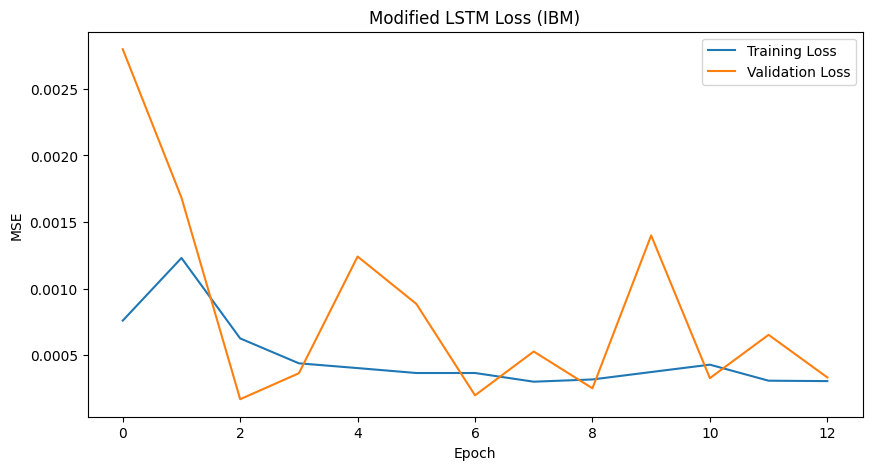

In [232]:
plt.figure(figsize=(10,5))
plt.plot(history_modified2.history['loss'], label='Training Loss')
plt.plot(history_modified2.history['val_loss'], label='Validation Loss')
plt.title('Modified LSTM Loss (IBM)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

### Gap Analysis

In [233]:
# Evaluasi model menggunakan bobot yang saat ini tersimpan
modified_train_loss2, modified_train_mae2 = modified_model2.evaluate(
    X_train_final2,
    y_train_final2,
    verbose=0
)

modified_val_loss2, modified_val_mae2 = modified_model2.evaluate(
    X_val2,
    y_val2,
    verbose=0
)

# Gap analysis
modified_loss_gap2 = modified_val_loss2 - modified_train_loss2
modified_gap_ratio2 = (modified_loss_gap2 / modified_train_loss2) * 100

print(f"Training Loss   : {modified_train_loss2:.6f}")
print(f"Validation Loss : {modified_val_loss2:.6f}")
print(f"Loss Gap        : {modified_loss_gap2:.6f}")
print(f"Gap Ratio       : {modified_gap_ratio2:.2f}%")

Training Loss   : 0.001636
Validation Loss : 0.000171
Loss Gap        : -0.001465
Gap Ratio       : -89.58%


### Prediction on Test Set

In [234]:
y_pred_modified2 = modified_model2.predict(X_test2)

y_test_actual_modified2 = scaler_ibm.inverse_transform(y_test2.reshape(-1,1))
y_pred_actual_modified2 = scaler_ibm.inverse_transform(y_pred_modified2)

8/8 [==============================] - 0s 1ms/step


### Compare Actual vs Predicted

In [235]:
comparison_modified2 = pd.DataFrame({
    'Actual Price': y_test_actual_modified2.flatten(),
    'Predicted Price': y_pred_actual_modified2.flatten()
})

comparison_modified2['Difference'] = (comparison_modified2['Actual Price'] - comparison_modified2['Predicted Price'])
comparison_modified2.head(10)

,Actual Price,Predicted Price,Difference
0,143.300003,139.955109,3.344894
1,143.000000,140.886780,2.113220
2,143.630005,141.816208,1.813797
3,142.779999,142.600433,0.179565
4,143.279999,142.880219,0.399780
5,143.389999,142.945801,0.444199
6,142.110001,142.990128,-0.880127
7,143.020004,142.757568,0.262436
8,143.779999,142.643738,1.136261
9,144.350006,142.817551,1.532455


### Visualisasi Actual vs Predicted

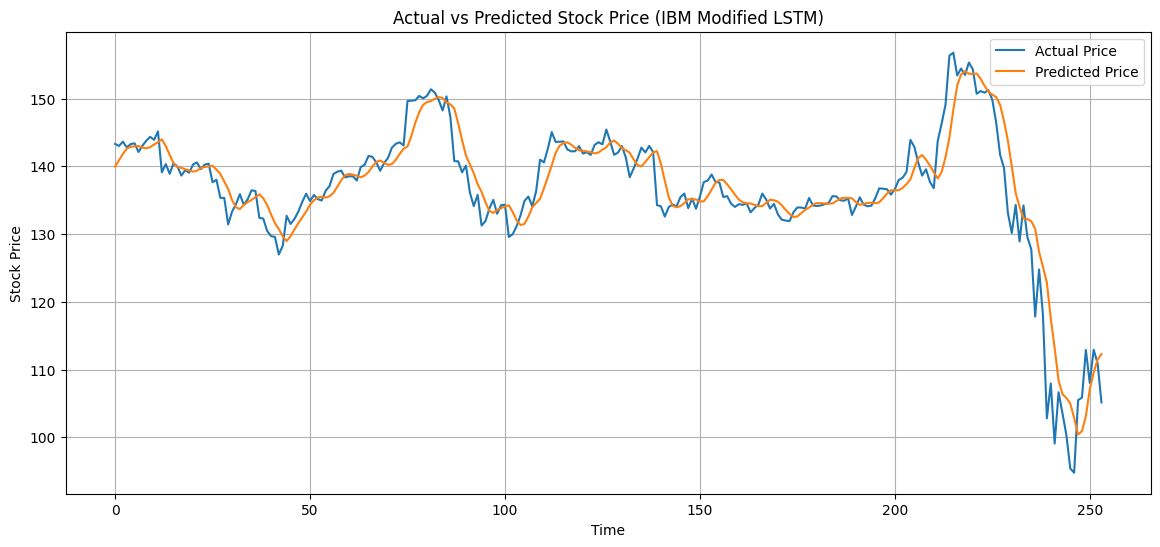

In [236]:
plt.figure(figsize=(14,6))
plt.plot(y_test_actual_modified2, label='Actual Price')
plt.plot(y_pred_actual_modified2, label='Predicted Price')
plt.title('Actual vs Predicted Stock Price (IBM Modified LSTM)')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.grid(True)
plt.show()

Grafik Actual vs Predicted Stock Price menunjukkan bahwa model belum mampu mengikuti pola pergerakan harga saham IBM dengan baik. Hal ini terlihat dari garis Predicted Price yang secara konsisten berada di atas garis Actual Price, sehingga terdapat selisih yang cukup besar hampir di seluruh periode pengujian. Meskipun model masih dapat menangkap kecenderungan naik dan turun harga saham, nilai prediksi yang dihasilkan memiliki bias yang cukup tinggi sehingga belum mampu merepresentasikan nilai aktual secara akurat.

### Evaluasi Metric

In [237]:
rmse2_modified = np.sqrt(mean_squared_error(y_test_actual_modified2, y_pred_actual_modified2))
mae2_modified = mean_absolute_error(y_test_actual_modified2, y_pred_actual_modified2)
mape2_modified = np.mean(np.abs((y_test_actual_modified2 - y_pred_actual_modified2)/ y_test_actual_modified2)) * 100

print('Evaluasi Modified LSTM (IBM)')
print(f"RMSE : {rmse2_modified:.4f}")
print(f"MAE  : {mae2_modified:.4f}")
print(f"MAPE : {mape2_modified:.4f}%")

Evaluasi Modified LSTM (IBM)
RMSE : 3.5302
MAE  : 2.2979
MAPE : 1.7672%


## Model Performance Evaluation

Membandingkan performa Baseline LSTM dan Modified LSTM pada data test set menggunakan tiga metrik evaluasi regresi, yaitu RMSE, MAE, dan MAPE.

Semakin kecil nilai RMSE, MAE, dan MAPE, maka semakin baik performa model dalam melakukan prediksi harga saham.

In [238]:
comparison_metric = pd.DataFrame({
    'Metric':[
        'RMSE',
        'MAE',
        'MAPE (%)'
    ],

    'Persistence FB':[
        rmse_persistence1,
        mae_persistence1,
        mape_persistence1
    ],
    
    'Persistence IBM':[
        rmse_persistence2,
        mae_persistence2,
        mape_persistence2
    ],

    'Baseline FB':[
        rmse1,
        mae1,
        mape1
    ],

    'Baseline IBM':[
        rmse2,
        mae2,
        mape2
    ],

    'Modified FB':[
        rmse1_modified,
        mae1_modified,
        mape1_modified
    ],

    'Modified IBM':[
        rmse2_modified,
        mae2_modified,
        mape2_modified
    ]
})

comparison_metric


,Metric,Persistence FB,Persistence IBM,Baseline FB,Baseline IBM,Modified FB,Modified IBM
0,RMSE,4.173537,2.689157,5.491194,2.663395,5.569056,3.530246
1,MAE,2.842716,1.720158,4.311142,1.781546,4.563561,2.297875
2,MAPE (%),1.548272,1.329784,2.265656,1.365667,2.415483,1.767220


Berdasarkan hasil evaluasi, **Modified LSTM pada dataset Facebook (FB) menunjukkan performa yang sedikit lebih buruk dibandingkan Baseline LSTM**. Hal ini terlihat dari peningkatan nilai RMSE dari 5.4912 menjadi 5.5691, MAE dari 4.3111 menjadi 4.5636, serta MAPE dari 2.2657% menjadi 2.4155%. Peningkatan nilai pada ketiga metrik tersebut menunjukkan bahwa model modifikasi menghasilkan kesalahan prediksi yang lebih besar dibandingkan model baseline. Dengan demikian, modifikasi arsitektur yang dilakukan belum berhasil meningkatkan performa prediksi pada dataset Facebook.

Sementara itu, pada dataset IBM, **Modified LSTM juga menghasilkan performa yang lebih rendah dibandingkan Baseline LSTM**. Hal ini terlihat dari peningkatan nilai RMSE dari 2.6634 menjadi 3.5302, MAE dari 1.7815 menjadi 2.2979, dan MAPE dari 1.3657% menjadi 1.7672%. Hasil ini menunjukkan bahwa perubahan arsitektur dan hyperparameter yang digunakan belum sesuai untuk meningkatkan kemampuan prediksi pada dataset IBM. Dengan kata lain, model modifikasi menghasilkan kesalahan prediksi yang lebih besar daripada model baseline pada ketiga metrik evaluasi.

Jika dibandingkan dengan Persistence Baseline, hasil evaluasi juga menunjukkan bahwa **model LSTM belum mampu memberikan performa terbaik secara konsisten pada kedua dataset**. Pada dataset Facebook, Persistence Baseline menghasilkan RMSE sebesar 4.1735, MAE sebesar 2.8427, dan MAPE sebesar 1.5483%, yang seluruhnya lebih rendah daripada Baseline maupun Modified LSTM. Sementara itu, pada dataset IBM, Baseline LSTM menghasilkan RMSE terbaik sebesar 2.6634, sedangkan Persistence Baseline menghasilkan MAE dan MAPE terbaik, masing-masing sebesar 1.7202 dan 1.3298%. Hasil tersebut menunjukkan bahwa model yang lebih kompleks tidak selalu menghasilkan prediksi yang lebih akurat dibandingkan model sederhana.

Meskipun telah dilakukan modifikasi arsitektur dan penyesuaian hyperparameter, performa Modified LSTM pada dataset Facebook maupun IBM masih belum mampu melampaui Baseline LSTM. Hal ini menunjukkan bahwa perubahan arsitektur belum memberikan peningkatan performa yang diharapkan. Jadi, dalam eksperimen ini, Baseline LSTM lebih unggul pada metrik RMSE untuk IBM, sedangkan Persistence Baseline memberikan hasil terbaik secara keseluruhan untuk Facebook serta pada metrik MAE dan MAPE untuk IBM.